In [1]:
# Install the Kaggle library
!pip install -q kaggle

import os
# Set the environment variable using your new token
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_dc688b1e6ea23cf7f23959d3148e497f'

# Alternatively, you can save it to the file Kaggle looks for (use the ! command)
!mkdir -p ~/.kaggle
!echo "YOUR_NEW_TOKEN_HERE" > ~/.kaggle/access_token
!chmod 600 ~/.kaggle/access_token

print("Kaggle token configured!")

Kaggle token configured!


In [2]:
# Download the dataset (this will take a minute or two)
!kaggle datasets download -d paultimothymooney/breast-histopathology-images

# Unzip it into a folder called IDC_dataset
!unzip -q breast-histopathology-images.zip -d IDC_dataset

print("Dataset downloaded and unzipped!")

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/breast-histopathology-images
License(s): CC0-1.0
100% 3.10G/3.10G [00:32<00:00, 103MB/s] 

Dataset downloaded and unzipped!


In [3]:
import os
BASE_DIR = "IDC_dataset/IDC_regular_ps50_idx5"
# This should print a list of patient ID folders like ['10253', '10254', ...]
print("Dataset folders:", os.listdir(BASE_DIR)[:5])

Dataset folders: ['15473', '12869', '12934', '13461', '14304']


In [4]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# This is the path we created earlier
BASE_DIR = "IDC_dataset/IDC_regular_ps50_idx5"

data = []
# Loop through every patient folder
for patient_id in os.listdir(BASE_DIR):
    patient_path = os.path.join(BASE_DIR, patient_id)
    if not os.path.isdir(patient_path):
        continue

    # Loop through class 0 (benign) and class 1 (malignant)
    for label in ["0", "1"]:
        label_path = os.path.join(patient_path, label)
        if not os.path.isdir(label_path):
            continue

        # Loop through every image in the folder
        for img_name in os.listdir(label_path):
            img_path = os.path.join(label_path, img_name)
            data.append({
                "patient_id": patient_id,
                "image_path": img_path,
                "label": int(label) # 0 = benign, 1 = malignant
            })

# Create the dataframe (table)
df = pd.DataFrame(data)
print(f"Total images found: {len(df):,}")

# --- PATIENT-LEVEL SPLIT ---
# Get a list of all unique patients
unique_patients = df["patient_id"].unique()

# Split the patients into 80% train, 20% test
train_patients, test_patients = train_test_split(
    unique_patients, test_size=0.2, random_state=42
)

# Create the final training and testing dataframes
train_df = df[df["patient_id"].isin(train_patients)].reset_index(drop=True)
test_df  = df[df["patient_id"].isin(test_patients)].reset_index(drop=True)

print("-" * 30)
print(f"Training Patients: {len(train_patients)} | Training Images: {len(train_df):,}")
print(f"Testing Patients:  {len(test_patients)} | Testing Images:  {len(test_df):,}")
print("-" * 30)
print("Class balance in training:")
print(train_df['label'].value_counts(normalize=True))

Total images found: 277,524
------------------------------
Training Patients: 223 | Training Images: 224,019
Testing Patients:  56 | Testing Images:  53,505
------------------------------
Class balance in training:
label
0    0.706681
1    0.293319
Name: proportion, dtype: float64


In [5]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.optimizers import Adam
from sklearn.utils import class_weight
import numpy as np

# 1. TAKE A SUBSET OF THE DATA (To save time)
# We will use 30,000 training images and 5,000 testing images
train_subset = train_df.sample(n=30000, random_state=42).reset_index(drop=True)
test_subset = test_df.sample(n=5000, random_state=42).reset_index(drop=True)

# Convert labels to string for the generator
train_subset['label'] = train_subset['label'].astype(str)
test_subset['label'] = test_subset['label'].astype(str)

# 2. SET UP IMAGE GENERATORS
# This loads images in small batches so Colab doesn't run out of RAM
train_datagen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    vertical_flip=True
)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_subset,
    x_col="image_path",
    y_col="label",
    target_size=(50, 50),
    batch_size=64,
    class_mode="binary",
    shuffle=True
)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_subset,
    x_col="image_path",
    y_col="label",
    target_size=(50, 50),
    batch_size=64,
    class_mode="binary",
    shuffle=False
)

# 3. HANDLE CLASS IMBALANCE
# Tell the model to pay more attention to the minority class (malignant)
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_subset['label']),
    y=train_subset['label']
)
class_weights_dict = {0: weights[0], 1: weights[1]}
print(f"Class weights applied: {class_weights_dict}")

# 4. BUILD THE CANCERNET MODEL
def build_cancernet(input_shape=(50, 50, 3)):
    model = Sequential([
        Conv2D(32, (3, 3), padding="same", input_shape=input_shape),
        Activation("relu"),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Conv2D(64, (3, 3), padding="same"),
        Activation("relu"),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Conv2D(128, (3, 3), padding="same"),
        Activation("relu"),
        BatchNormalization(),
        MaxPooling2D(pool_size=(2, 2)),
        Dropout(0.25),

        Flatten(),
        Dense(256),
        Activation("relu"),
        BatchNormalization(),
        Dropout(0.5),
        Dense(1),
        Activation("sigmoid")
    ])
    return model

model = build_cancernet()
model.compile(
    loss="binary_crossentropy",
    optimizer=Adam(learning_rate=0.001),
    metrics=["accuracy", tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

# 5. TRAIN FOR 5 EPOCHS
print("\nStarting training for 5 epochs...")
history_5 = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=5,
    validation_data=test_generator,
    validation_steps=len(test_generator),
    class_weight=class_weights_dict
)

Found 30000 validated image filenames belonging to 2 classes.
Found 5000 validated image filenames belonging to 2 classes.
Class weights applied: {0: np.float64(0.7103618109490434), 1: np.float64(1.6884286357496623)}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Starting training for 5 epochs...
Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 66s 96ms/step - accuracy: 0.8074 - loss: 0.4770 - precision: 0.6430 - recall: 0.7861 - val_accuracy: 0.3176 - val_loss: 2.1872 - val_precision: 0.2636 - val_recall: 0.9975
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 40s 39ms/step - accuracy: 0.8333 - loss: 0.4014 - precision: 0.6821 - recall: 0.8187 - val_accuracy: 0.8054 - val_loss: 0.4801 - val_precision: 0.6866 - val_recall: 0.3761
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.8348 - loss: 0.3898 - precision: 0.6826 - recall: 0.8261 - val_accuracy: 0.5974 - val_loss: 0.7830 - val_precision: 0.3740 - val_recall: 0.9583
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.8386 - loss: 0.3814 - precision: 0.6893 - recall: 0.8281 - val_accuracy: 0.8146 - val_loss: 0.4970 - val_precision: 0.7044 - val_recall: 0.4170
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.8425 - loss: 0.3697 - precision: 0.6939 - recall: 0.83

79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 84ms/step
Confusion Matrix:
 [[1446 2331]
 [  66 1157]]

Classification Report:
               precision    recall  f1-score   support

      Benign       0.96      0.38      0.55      3777
   Malignant       0.33      0.95      0.49      1223

    accuracy                           0.52      5000
   macro avg       0.64      0.66      0.52      5000
weighted avg       0.80      0.52      0.53      5000



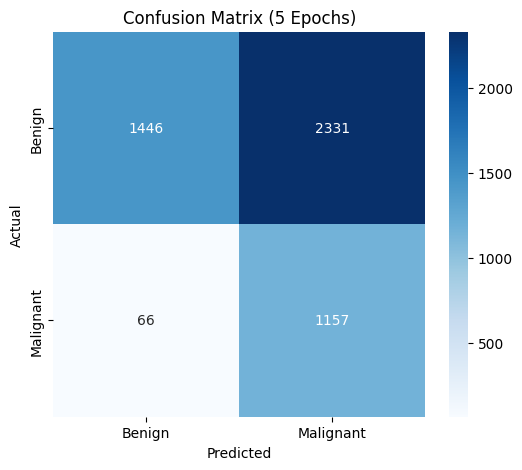

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Get predictions
# It's crucial to reset the generator so it predicts in the exact same order as the dataframe
test_generator.reset()
predictions = model.predict(test_generator, steps=len(test_generator))
y_pred = (predictions > 0.5).astype(int).flatten()

# 2. Get true labels (since generator converts them to strings, we do the same)
y_true = test_subset['label'].astype(int).values

# 3. Print Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

# 4. Print Classification Report
print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=["Benign", "Malignant"]))

# 5. Plot it nicely
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benign", "Malignant"],
            yticklabels=["Benign", "Malignant"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (5 Epochs)")
plt.show()

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# 1. Build a FRESH model
model_10 = build_cancernet()
# Lower learning rate to stabilize training
model_10.compile(
    loss="binary_crossentropy",
    optimizer=Adam(learning_rate=0.0001), # Changed from 0.001
    metrics=["accuracy", tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

# 2. Set up callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-6)
# This saves the best model directly to your Google Drive!
checkpoint = ModelCheckpoint('/content/drive/MyDrive/CancerNet_Best.h5', monitor='val_accuracy', save_best_only=True)

# 3. Train for 10 Epochs
print("Starting training for 10 epochs...")
history_10 = model_10.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=10,
    validation_data=test_generator,
    validation_steps=len(test_generator),
    class_weight=class_weights_dict,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Starting training for 10 epochs...
Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.7189 - loss: 0.6422 - precision: 0.5196 - recall: 0.7754

469/469 ━━━━━━━━━━━━━━━━━━━━ 40s 59ms/step - accuracy: 0.7450 - loss: 0.5855 - precision: 0.5481 - recall: 0.7920 - val_accuracy: 0.2464 - val_loss: 5.3676 - val_precision: 0.2450 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/10
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7763 - loss: 0.5158 - precision: 0.5906 - recall: 0.7904

469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 43ms/step - accuracy: 0.7822 - loss: 0.5072 - precision: 0.6004 - recall: 0.7903 - val_accuracy: 0.5046 - val_loss: 1.3773 - val_precision: 0.3272 - val_recall: 0.9706 - learning_rate: 1.0000e-04
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7983 - loss: 0.4821 - precision: 0.6230 - recall: 0.8049

469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.7992 - loss: 0.4778 - precision: 0.6264 - recall: 0.7982 - val_accuracy: 0.5610 - val_loss: 1.2708 - val_precision: 0.3534 - val_recall: 0.9583 - learning_rate: 1.0000e-04
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.8106 - loss: 0.4496 - precision: 0.6443 - recall: 0.8050 - val_accuracy: 0.5348 - val_loss: 1.3670 - val_precision: 0.3414 - val_recall: 0.9706 - learning_rate: 1.0000e-04
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8175 - loss: 0.4420 - precision: 0.6577 - recall: 0.7959

469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.8190 - loss: 0.4364 - precision: 0.6601 - recall: 0.8017 - val_accuracy: 0.6252 - val_loss: 1.2428 - val_precision: 0.3895 - val_recall: 0.9387 - learning_rate: 5.0000e-05
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.8217 - loss: 0.4248 - precision: 0.6617 - recall: 0.8143 - val_accuracy: 0.5160 - val_loss: 1.4326 - val_precision: 0.3326 - val_recall: 0.9722 - learning_rate: 5.0000e-05
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8244 - loss: 0.4163 - precision: 0.6636 - recall: 0.8183

469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - accuracy: 0.8214 - loss: 0.4234 - precision: 0.6616 - recall: 0.8127 - val_accuracy: 0.7208 - val_loss: 0.8617 - val_precision: 0.4637 - val_recall: 0.9043 - learning_rate: 2.5000e-05
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - accuracy: 0.8232 - loss: 0.4194 - precision: 0.6650 - recall: 0.8119 - val_accuracy: 0.6716 - val_loss: 1.0038 - val_precision: 0.4223 - val_recall: 0.9305 - learning_rate: 2.5000e-05
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.8273 - loss: 0.4094 - precision: 0.6680 - recall: 0.8286 - val_accuracy: 0.6798 - val_loss: 0.9841 - val_precision: 0.4281 - val_recall: 0.9199 - learning_rate: 1.2500e-05
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.8262 - loss: 0.4134 - precision: 0.6680 - recall: 0.8213 - val_accuracy: 0.6850 - val_loss: 0.9650 - val_precision: 0.4325 - val_recall: 0.9223 - learning_rate: 6.2500e-06


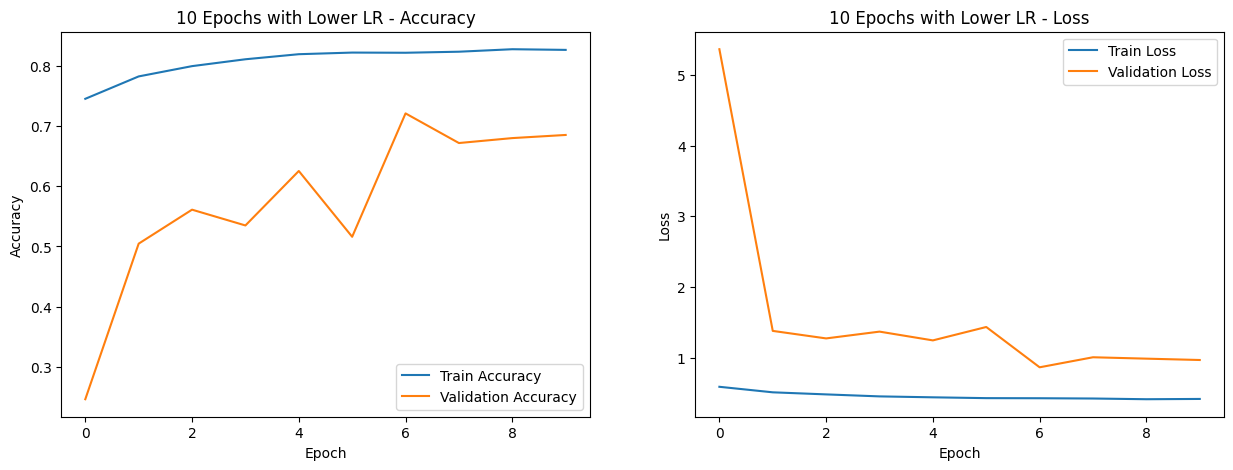

In [9]:
import matplotlib.pyplot as plt

def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))

    # Accuracy
    ax[0].plot(history.history['accuracy'], label='Train Accuracy')
    ax[0].plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax[0].set_title(f'{title} - Accuracy')
    ax[0].set_ylabel('Accuracy')
    ax[0].set_xlabel('Epoch')
    ax[0].legend()

    # Loss
    ax[1].plot(history.history['loss'], label='Train Loss')
    ax[1].plot(history.history['val_loss'], label='Validation Loss')
    ax[1].set_title(f'{title} - Loss')
    ax[1].set_ylabel('Loss')
    ax[1].set_xlabel('Epoch')
    ax[1].legend()

    plt.show()

plot_history(history_10, "10 Epochs with Lower LR")